# Spatial DO Trend Mapping: Method Comparison with Statistical Significance

This notebook analyzes long-term bottom Dissolved Oxygen (DO) trends across coastal water masses and compares three distinct statistical frameworks:
1. **Version 80a: Ordinary Least Squares (OLS) Linear Regression** ($p$-value from Student's t-test)
2. **Version 80b: Pearson Correlation Coefficient ($r$)** ($p$-value from bivariate correlation t-test)
3. **Version 80c: Mann-Kendall Test & Sen's Slope** ($p$-value from non-parametric rank test, magnitude from Theil-Sen estimator)

In earlier pipeline steps (e.g., `step2/process13`), linear trends were interpolated across all stations without filtering for statistical significance ($p < 0.05$). This notebook evaluates how applying significance filtering affects spatial trend patterns, compares parametric vs. non-parametric methods, and provides side-by-side spatial maps.

---

### Method Comparison Summary

| Dimension | Linear Regression (OLS) | Pearson Correlation ($r$) | Mann-Kendall + Sen's Slope |
| :--- | :--- | :--- | :--- |
| **Statistical Type** | Parametric | Parametric | Non-parametric (Rank-based) |
| **Mapped Metric** | Slope ($a$, mg/L / year) | Correlation coefficient ($r$, $[-1, 1]$) | Median pairwise slope ($a_{\text{Sen}}$, mg/L / year) |
| **Relationship Tested** | Linear rate of change | Linear association tightness | Monotonic trend (upward/downward) |
| **Significance Test** | Student's t-test ($H_0: a = 0$) | Student's t-test ($H_0: r = 0$) | Asymptotic normal $Z$-test ($H_0: \tau = 0$) |
| **Data Assumptions** | Normal residuals, homoscedasticity | Bivariate normal distribution | None (distribution-free) |
| **Outlier Sensitivity** | **High** (single extreme year alters slope) | **High** (outliers skew variance) | **Very Low** (uses pairwise median) |
| **Best Application** | Physical rate estimation when data is well-behaved | Assessing consistency of linear trajectory | Environmental/climate time-series with noise or skewness |


In [1]:
import sys
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy import stats, ndimage
from scipy.spatial import cKDTree
from shapely.geometry import Point, box
from shapely.prepared import prep
from pyproj import Transformer
import matplotlib.pyplot as plt
import matplotlib.path as mpath
from matplotlib.patches import Polygon as MplPolygon, PathPatch
from matplotlib.collections import PatchCollection
import cartopy.crs as ccrs
import cartopy.feature as cfeature

warnings.filterwarnings('ignore')

# Project root path resolution
PROJECT_ROOT = Path('.').resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.paths import ProjectPaths
from utils.mapping_config import MappingConfig
from utils.data_loader import load_and_process_data

MappingConfig.apply_global_plot_styles()
print("Environment and modules successfully initialized.")


Environment and modules successfully initialized.


## 1. Station-Level Trend & Significance Calculation

We evaluate bottom DO (`saisuipoin == 2`) during Summer across monitoring stations.
For each station with at least 5 years of observations:
- **Linear Regression**: Fits $y = ax + b$ via `scipy.stats.linregress`.
- **Pearson Correlation**: Calculates $r$ and $p$-value via `scipy.stats.pearsonr`.
- **Mann-Kendall & Sen's Slope**: Evaluates Kendall's $\tau$ via `scipy.stats.kendalltau` and median slope via `scipy.stats.theilslopes`.


In [2]:
TARGET_DIVISION = 'Tokyo Bay'
TARGET_SEASON = 'Summer'
ALPHA = 0.05
MIN_YEARS = 5

merged_gdf = load_and_process_data(force_reload=False)
df = merged_gdf[(merged_gdf['season'] == TARGET_SEASON) & (merged_gdf['saisuipoin'] == 2)].copy()
df['do_'] = pd.to_numeric(df['do_'], errors='coerce')
df = df.dropna(subset=['do_'])

if TARGET_DIVISION in ['Tokyo Bay', 'Ise Bay', 'Seto Inland Sea']:
    df = df[df['watermass_name'] == TARGET_DIVISION]
else:
    df = df[df['division'] == TARGET_DIVISION]

records = []
for station, group in df.groupby('zettaicode'):
    group = group.dropna(subset=['year', 'do_'])
    if len(group) < MIN_YEARS:
        continue
    
    years = group['year'].values
    do_vals = group['do_'].values
    
    # Method 1: OLS Linear Regression
    lr = stats.linregress(years, do_vals)
    
    # Method 2: Pearson Correlation
    pr_r, pr_p = stats.pearsonr(years, do_vals)
    
    # Method 3: Mann-Kendall & Sen's Slope
    mk = stats.kendalltau(years, do_vals)
    sen = stats.theilslopes(do_vals, years)
    
    records.append({
        'zettaicode': station,
        'longitude': group['longitude'].iloc[0],
        'latitude': group['latitude'].iloc[0],
        'n_years': len(group),
        'lr_slope': lr.slope,
        'lr_pvalue': lr.pvalue,
        'lr_sig': bool(lr.pvalue < ALPHA),
        'pearson_r': pr_r,
        'pearson_pvalue': pr_p,
        'pearson_sig': bool(pr_p < ALPHA),
        'kendall_tau': mk.statistic,
        'mk_pvalue': mk.pvalue,
        'sen_slope': sen.slope,
        'mk_sig': bool(mk.pvalue < ALPHA),
    })

comparison_df = pd.DataFrame(records)
print(f"Region: {TARGET_DIVISION}")
print(f"Total stations analyzed: {len(comparison_df)}")
print(f"Significant (p < {ALPHA}):")
print(f"  - Linear Regression (OLS): {comparison_df['lr_sig'].sum()} / {len(comparison_df)} stations")
print(f"  - Pearson Correlation:    {comparison_df['pearson_sig'].sum()} / {len(comparison_df)} stations")
print(f"  - Mann-Kendall Test:      {comparison_df['mk_sig'].sum()} / {len(comparison_df)} stations")

display(comparison_df.head(10))


Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Region: Tokyo Bay
Total stations analyzed: 28
Significant (p < 0.05):
  - Linear Regression (OLS): 5 / 28 stations
  - Pearson Correlation:    5 / 28 stations
  - Mann-Kendall Test:      4 / 28 stations


,zettaicode,longitude,latitude,n_years,lr_slope,lr_pvalue,lr_sig,pearson_r,pearson_pvalue,pearson_sig,kendall_tau,mk_pvalue,sen_slope,mk_sig
0,00000122,139.990000,35.647222,39,0.037716,0.412720,False,0.134953,0.412720,False,0.090786,0.417454,0.039565,False
1,00000124,140.060833,35.605000,42,-0.017081,0.658709,False,-0.070189,0.658709,False,-0.059441,0.580331,-0.026282,False
2,00000125,139.962778,35.607500,36,0.062150,0.072852,False,0.302586,0.072852,False,0.225423,0.054527,0.055556,False
3,00000128,140.073333,35.565000,42,0.053217,0.093003,False,0.262547,0.093003,False,0.153219,0.155388,0.042857,False
4,00000129,140.019167,35.540556,40,-0.000335,0.985536,False,-0.002960,0.985536,False,-0.002601,0.981376,0.000000,False
5,00001210,139.985000,35.573056,36,0.088828,0.005998,True,0.449145,0.005998,True,0.324025,0.005660,0.076190,True
6,00001212,139.895000,35.611667,39,-0.017993,0.628493,False,-0.079955,0.628493,False,-0.059743,0.594284,-0.025000,False
7,00001214,139.946667,35.535000,38,0.000669,0.970387,False,0.006230,0.970387,False,-0.005768,0.959820,0.000000,False
8,00001215,139.905556,35.554444,36,0.005831,0.763089,False,0.052040,0.763089,False,0.041668,0.722903,0.005556,False
9,00001222,139.906667,35.488333,42,0.005386,0.751674,False,0.050314,0.751674,False,0.012881,0.905015,0.000000,False


## 2. Statistical Comparison: Parametric vs. Non-Parametric

Below we compare:
1. **OLS Slope vs. Sen's Slope**: Checks whether extreme years or non-linear fluctuations pull the OLS regression line away from the robust Theil-Sen median slope.
2. **P-Value Agreement**: Examines whether the Student's t-test and the Mann-Kendall rank test agree on which stations have statistically significant trends.


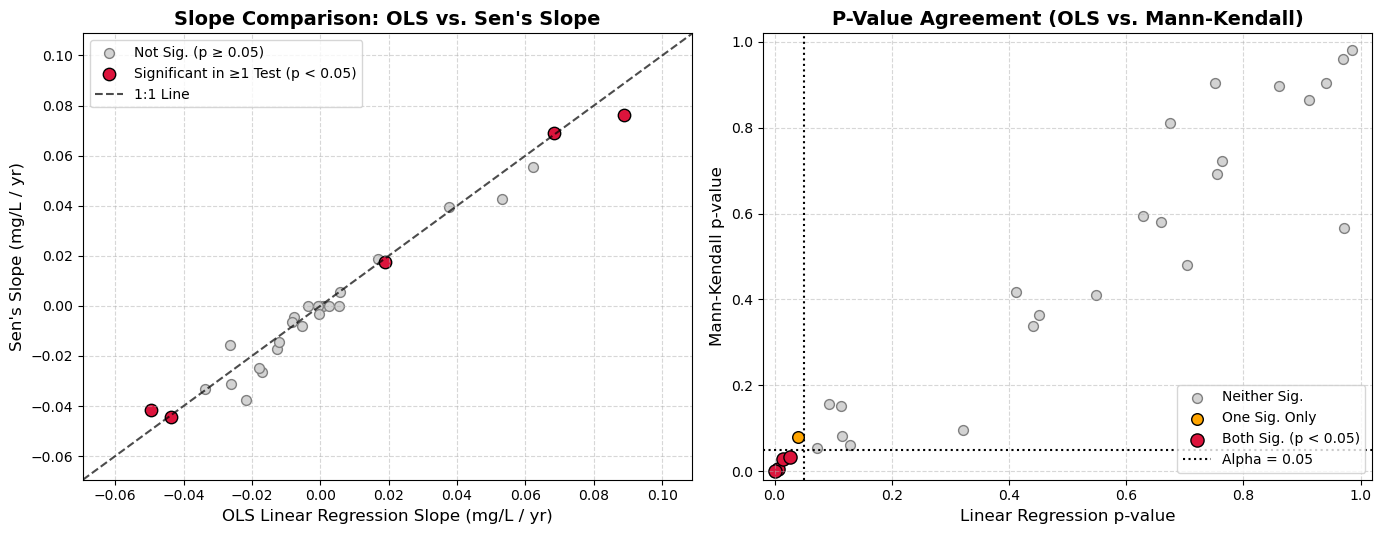

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Slope Comparison (OLS vs Sen's Slope)
ax1 = axes[0]
sig_mask = comparison_df['lr_sig'] | comparison_df['mk_sig']

ax1.scatter(comparison_df.loc[~sig_mask, 'lr_slope'], comparison_df.loc[~sig_mask, 'sen_slope'],
            c='lightgray', s=50, edgecolors='gray', label=f'Not Sig. (p ≥ {ALPHA})')
ax1.scatter(comparison_df.loc[sig_mask, 'lr_slope'], comparison_df.loc[sig_mask, 'sen_slope'],
            c='crimson', s=80, edgecolors='black', label=f'Significant in ≥1 Test (p < {ALPHA})')

all_slopes = np.concatenate([comparison_df['lr_slope'].values, comparison_df['sen_slope'].values])
s_min, s_max = all_slopes.min() - 0.02, all_slopes.max() + 0.02
ax1.plot([s_min, s_max], [s_min, s_max], 'k--', alpha=0.7, label='1:1 Line')
ax1.set_xlim(s_min, s_max)
ax1.set_ylim(s_min, s_max)
ax1.set_xlabel('OLS Linear Regression Slope (mg/L / yr)', fontsize=12)
ax1.set_ylabel("Sen's Slope (mg/L / yr)", fontsize=12)
ax1.set_title("Slope Comparison: OLS vs. Sen's Slope", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left', fontsize=10)

# 2. P-value Comparison
ax2 = axes[1]
both_sig = comparison_df['lr_sig'] & comparison_df['mk_sig']
either_sig = sig_mask & (~both_sig)
neither_sig = ~sig_mask

ax2.scatter(comparison_df.loc[neither_sig, 'lr_pvalue'], comparison_df.loc[neither_sig, 'mk_pvalue'],
            c='lightgray', s=50, edgecolors='gray', label='Neither Sig.')
ax2.scatter(comparison_df.loc[either_sig, 'lr_pvalue'], comparison_df.loc[either_sig, 'mk_pvalue'],
            c='orange', s=70, edgecolors='black', label='One Sig. Only')
ax2.scatter(comparison_df.loc[both_sig, 'lr_pvalue'], comparison_df.loc[both_sig, 'mk_pvalue'],
            c='crimson', s=90, edgecolors='black', label='Both Sig. (p < 0.05)')

ax2.axvline(ALPHA, color='black', linestyle=':', lw=1.5, label=f'Alpha = {ALPHA}')
ax2.axhline(ALPHA, color='black', linestyle=':', lw=1.5)
ax2.set_xlim(-0.02, 1.02)
ax2.set_ylim(-0.02, 1.02)
ax2.set_xlabel('Linear Regression p-value', fontsize=12)
ax2.set_ylabel('Mann-Kendall p-value', fontsize=12)
ax2.set_title('P-Value Agreement (OLS vs. Mann-Kendall)', fontsize=14, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()


## 3. Multi-Panel Spatial Mapping of Statistically Significant Trends

We now apply diffusion interpolation within the geographic water mask boundary for all three methods side-by-side:
- **Left Panel (80a)**: OLS Linear Regression Slope (mg/L / yr)
- **Center Panel (80b)**: Pearson Correlation Coefficient ($r$)
- **Right Panel (80c)**: Mann-Kendall / Sen's Slope (mg/L / yr)

In each panel:
- **Solid black circles ($●$)**: Stations with statistically significant trends ($p < 0.05$).
- **Gray crosses ($×$)**: Evaluated stations where trends were not statistically significant ($p \ge 0.05$).


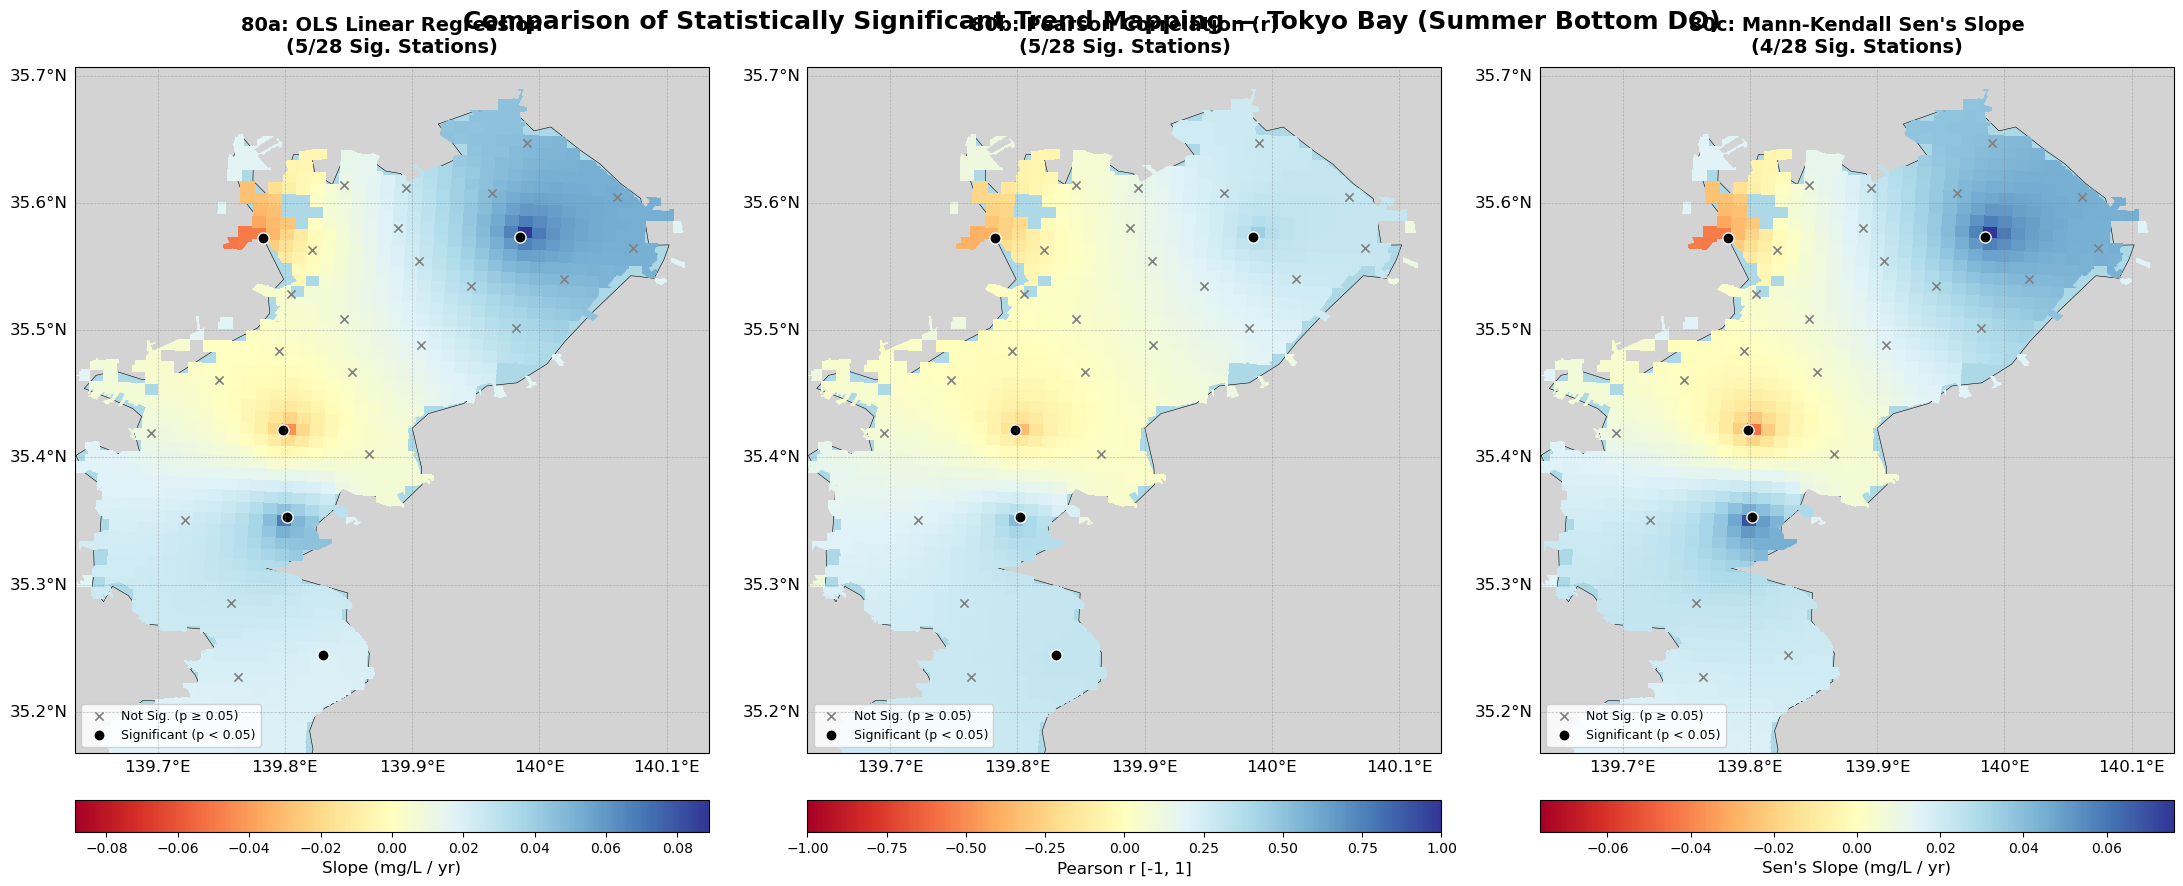

In [4]:
def load_spatial_data(division):
    if division == 'Tokyo Bay':
        lb = gpd.read_file(ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Tokyobay_boundary.shp')
        wm = gpd.read_file(ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_Tokyo.shp')
    elif division == 'Ise Bay':
        lb = gpd.read_file(ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Isebay_boundary.shp')
        wm = gpd.read_file(ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_Ise.shp')
    else:
        lb = gpd.read_file(ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Setonaikai_boundary_2.shp')
        wm = gpd.read_file(ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_sis_simplified.shp')
    return lb.to_crs("EPSG:4326"), wm.to_crs("EPSG:4326")

def setup_diffusion_grid(water_boundary_gdf, data_bounds, grid_res=1000):
    utm_crs = 'EPSG:32653'
    water_utm = water_boundary_gdf.to_crs(utm_crs)
    data_bounds_gdf = gpd.GeoDataFrame({'geometry': [Point(data_bounds[0], data_bounds[1]), Point(data_bounds[2], data_bounds[3])]}, crs="EPSG:4326")
    data_bounds_utm = data_bounds_gdf.to_crs(utm_crs).total_bounds

    minx, miny = data_bounds_utm[0] - 2000, data_bounds_utm[1] - 2000
    maxx, maxy = data_bounds_utm[2] + 2000, data_bounds_utm[3] + 2000
    grid_x_1d = np.arange(minx, maxx, grid_res)
    grid_y_1d = np.arange(miny, maxy, grid_res)
    grid_x, grid_y = np.meshgrid(grid_x_1d, grid_y_1d)

    water_poly = prep(water_utm.geometry.union_all())
    flat_x, flat_y = grid_x.flatten(), grid_y.flatten()
    grid_pts = [Point(x, y) for x, y in zip(flat_x, flat_y)]
    water_mask = np.array([water_poly.contains(pt) for pt in grid_pts]).reshape(grid_x.shape)

    transformer = Transformer.from_crs(utm_crs, "EPSG:4326", always_xy=True)
    lon_flat, lat_flat = transformer.transform(flat_x, flat_y)
    lon_wgs = lon_flat.reshape(grid_x.shape)
    lat_wgs = lat_flat.reshape(grid_y.shape)

    kernel = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])
    W = ndimage.convolve(water_mask.astype(float), kernel, mode='constant', cval=0.0)
    valid_W_mask = W > 0
    i_idx, j_idx = np.indices(grid_x.shape)
    red_mask = (i_idx + j_idx) % 2 == 0
    black_mask = ~red_mask

    water_iy, water_ix = np.where(water_mask)
    water_coords = np.column_stack([grid_x[water_iy, water_ix], grid_y[water_iy, water_ix]])
    water_tree = cKDTree(water_coords)

    return {
        'grid_x': grid_x, 'grid_y': grid_y, 'lon_wgs': lon_wgs, 'lat_wgs': lat_wgs,
        'water_mask': water_mask, 'valid_W_mask': valid_W_mask, 'W': W,
        'red_mask': red_mask, 'black_mask': black_mask, 'water_tree': water_tree,
        'water_iy': water_iy, 'water_ix': water_ix, 'kernel': kernel, 'utm_crs': utm_crs
    }

def run_diffusion_interpolation(vals, pts_x, pts_y, grid_info, max_iters=500, tol=1e-3, omega=1.8):
    water_mask = grid_info['water_mask']
    Z = np.full(water_mask.shape, np.nan)
    Z[water_mask] = np.nanmean(vals)
    fixed_mask = np.zeros_like(water_mask, dtype=bool)

    coords = np.column_stack([pts_x, pts_y])
    _, nearest_idx = grid_info['water_tree'].query(coords)
    w_iy, w_ix = grid_info['water_iy'], grid_info['water_ix']
    for k in range(len(vals)):
        iy, ix = w_iy[nearest_idx[k]], w_ix[nearest_idx[k]]
        Z[iy, ix] = vals[k]
        fixed_mask[iy, ix] = True

    Z_water = np.zeros_like(Z)
    kernel, valid_W_mask, W = grid_info['kernel'], grid_info['valid_W_mask'], grid_info['W']
    red_mask, black_mask = grid_info['red_mask'], grid_info['black_mask']

    for it in range(max_iters):
        Z_old = Z[water_mask].copy()
        with np.errstate(divide='ignore', invalid='ignore'):
            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            up_r = red_mask & water_mask & (~fixed_mask)
            Z[up_r] = (1 - omega) * Z[up_r] + omega * Z_avg[up_r]

            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            up_b = black_mask & water_mask & (~fixed_mask)
            Z[up_b] = (1 - omega) * Z[up_b] + omega * Z_avg[up_b]

        if np.max(np.abs(Z[water_mask] - Z_old)) < tol:
            break
    return Z

def gdf_to_clip_path(gdf):
    union_geom = gdf.geometry.union_all()
    verts, codes = [], []
    polys = [union_geom] if union_geom.geom_type == 'Polygon' else list(union_geom.geoms)
    for poly in polys:
        coords = np.array(poly.exterior.coords)
        verts.extend(coords)
        codes.append(mpath.Path.MOVETO)
        codes.extend([mpath.Path.LINETO] * (len(coords) - 2))
        codes.append(mpath.Path.CLOSEPOLY)
    return mpath.Path(verts, codes)

# Setup Spatial Data
land_bnd, water_msk = load_spatial_data(TARGET_DIVISION)
uniform_extent = MappingConfig.get_dynamic_extent(TARGET_DIVISION, plot_data=df)
bbox_geom = box(uniform_extent[0], uniform_extent[2], uniform_extent[1], uniform_extent[3])
clipped_water_mask = gpd.GeoDataFrame(geometry=[water_msk.geometry.union_all().buffer(0).intersection(bbox_geom).buffer(0)], crs="EPSG:4326")
grid_info = setup_diffusion_grid(water_msk, [uniform_extent[0], uniform_extent[2], uniform_extent[1], uniform_extent[3]])

# Prepare three panels
fig, axes = plt.subplots(1, 3, figsize=(22, 9), subplot_kw={'projection': ccrs.PlateCarree()})

configs = [
    {
        'title': f'80a: OLS Linear Regression\n({comparison_df["lr_sig"].sum()}/{len(comparison_df)} Sig. Stations)',
        'val_col': 'lr_slope', 'sig_col': 'lr_sig', 'cbar_label': 'Slope (mg/L / yr)',
        'is_corr': False
    },
    {
        'title': f'80b: Pearson Correlation (r)\n({comparison_df["pearson_sig"].sum()}/{len(comparison_df)} Sig. Stations)',
        'val_col': 'pearson_r', 'sig_col': 'pearson_sig', 'cbar_label': 'Pearson r [-1, 1]',
        'is_corr': True
    },
    {
        "title": f"80c: Mann-Kendall Sen's Slope\n({comparison_df['mk_sig'].sum()}/{len(comparison_df)} Sig. Stations)",
        "val_col": "sen_slope", "sig_col": "mk_sig", "cbar_label": "Sen's Slope (mg/L / yr)",
        "is_corr": False
    }
]

for idx, cfg in enumerate(configs):
    ax = axes[idx]
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=0)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.4, edgecolor='black', zorder=1)
    ax.set_extent(uniform_extent, crs=ccrs.PlateCarree())
    
    # Filter to significant stations
    sig_sub = comparison_df[comparison_df[cfg['sig_col']]]
    non_sig = comparison_df[~comparison_df[cfg['sig_col']]]
    
    sig_gdf = gpd.GeoDataFrame(sig_sub, geometry=[Point(xy) for xy in zip(sig_sub.longitude, sig_sub.latitude)], crs='EPSG:4326').to_crs(grid_info['utm_crs'])
    Z = run_diffusion_interpolation(sig_sub[cfg['val_col']].values, sig_gdf.geometry.x.values, sig_gdf.geometry.y.values, grid_info)
    
    if cfg['is_corr']:
        vmax = 1.0
    else:
        vmax = max(abs(np.nanmin(Z)), abs(np.nanmax(Z)))
        if vmax == 0: vmax = 0.1
    vmin = -vmax
    
    cm = ax.pcolormesh(grid_info['lon_wgs'], grid_info['lat_wgs'], Z,
                       transform=ccrs.PlateCarree(), cmap='RdYlBu', shading='nearest',
                       vmin=vmin, vmax=vmax, zorder=2)
    cm.set_clip_path(PathPatch(gdf_to_clip_path(clipped_water_mask), transform=ax.transData))
    
    # Plot non-significant and significant stations
    ax.scatter(non_sig['longitude'], non_sig['latitude'], c='gray', marker='x', s=35, linewidths=1.2,
               label=f'Not Sig. (p ≥ {ALPHA})', zorder=3, transform=ccrs.PlateCarree())
    ax.scatter(sig_sub['longitude'], sig_sub['latitude'], c='black', marker='o', s=65, edgecolors='white', linewidths=1.0,
               label=f'Significant (p < {ALPHA})', zorder=4, transform=ccrs.PlateCarree())
    
    ax.set_title(cfg['title'], fontsize=14, fontweight='bold', pad=10)
    MappingConfig.apply_gridlines(ax)
    
    cbar = fig.colorbar(cm, ax=ax, orientation='horizontal', fraction=0.046, pad=0.06)
    cbar.set_label(cfg['cbar_label'], fontsize=12)
    ax.legend(loc='lower left', frameon=True, framealpha=0.85, fontsize=9)

plt.suptitle(f"Comparison of Statistically Significant Trend Mapping — {TARGET_DIVISION} ({TARGET_SEASON} Bottom DO)",
             fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## 4. Key Scientific Insights

1. **Impact of Significance Filtering**:
   - In unmasked maps, stations with non-significant trends (random noise) receive full weight in the spatial interpolation, potentially creating the illusion of bay-wide deoxygenation or reoxygenation.
   - Restricting the interpolated field to statistically significant stations ($p < 0.05$) clarifies that only a subset of stations (e.g. 4–5 out of 28 in Tokyo Bay) exhibit confirmed multi-decadal trends.

2. **Linear Regression (80a) vs. Mann-Kendall (80c)**:
   - Parametric OLS regression is vulnerable to single extreme years (e.g., typhoon events or unusual heatwaves) that pull the regression line.
   - The Mann-Kendall test relies on relative ranks rather than parametric assumptions, and Sen's slope uses the median of pairwise slopes. It provides a more robust and conservative estimate of long-term environmental changes.

3. **Pearson Correlation (80b)**:
   - While OLS and Sen's slope describe the **rate** of DO change (in mg/L/year), Pearson correlation captures the **consistency** of that trajectory regardless of steepness.
   - It is especially helpful when comparing basins with very different baseline oxygen levels.
